# Absent target: NK signature on blood with NK cells removed (reviewer #2, major concern)

Domínguez Conde et al. blood (BLD), SIGMA input file. One NK configuration, fixed before
looking at the results, run twice with `find_target.py` (no QC, no harmonization, no merge):

- **all NK**: every cell (positive control, compared with the author labels)
- **no NK**: every NK-labelled cell removed, and the "Cycling T&NK" cells that mix T and NK
  (the reviewer's test)

For each run: candidates, whether a target component passed M, cells with score ≥ 0.95 and
their author labels.

In [1]:
import json
import os
import re
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

In [2]:
INPUT = ("/mnt/projects_tn03/AD_EB_singlecell/articleSIGMA_results-2/Dominguez-Data/forSIGMA/"
         "Dominguez_science_science-abl5197_BLD_data.h5ad")
SIGMA_SCRIPTS = "/home/lemgui01/SIGMA/scripts"
SIGMA_PYTHON = "/home/lemgui01/.miniconda3/envs/SIGMA/bin/python"  # SIGMA environment, whatever the kernel
WORK_DIR = "results/nk_absent"
FIG_DIR = "figures/"

# Author label column: the first one found is used
LABEL_COLUMNS = ["Manually_curated_celltype", "cell_type", "celltype", "Majority_voting_CellTypist"]
NK_PATTERN = r"^NK"  # author labels counted as NK; check the printed list below
AMBIGUOUS_PATTERN = r"Cycling T&NK"  # mixes T and NK cells: removed from no_NK, counted apart

# NK configuration, fixed before the runs
CANDIDATE = ["KLRF1", "NCR1", "SH2D1B"]  # NK lineage markers
TARGET = ["KLRF1", "NCAM1", "SH2D1B", "NCR1", "FCGR3A", "KLRC1", "GNLY", "NKG7", "PRF1", "GZMB"]
EXCLUDE = {
    "T_cells": ["CD3E", "CD3D", "CD3G", "TRAC", "TRBC1", "TRBC2", "CD5", "CD28"],
    "B_cells": ["MS4A1", "CD79A", "CD79B", "CD19", "PAX5"],
    "Monocytes": ["CD14", "LYZ", "FCN1", "CST3", "S100A8", "S100A9"],
}
EXCLUDE_CELLTYPES = "True"  # exclusion signatures are full competing lineages
MIN_GENES_DETECTED = 2
# Raw counts for a candidate gene to count as detected: 2 = first setting (171 of 3,984 NK
# passed the prefilter); 1 = second setting, these NK transcripts being poorly captured.
# Run-name suffix -> threshold
DETECTION_SETTINGS = {"": 2, "_t1": 1}
MIN_MEAN_EXPRESSION = 2
SCORE_THRESHOLD = 0.95

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Data and NK labels

In [3]:
adata = sc.read_h5ad(INPUT)
label_col = next(c for c in LABEL_COLUMNS if c in adata.obs.columns)
labels = adata.obs[label_col].astype(str)
is_nk = labels.str.contains(NK_PATTERN, regex=True).values
is_ambiguous = labels.str.contains(AMBIGUOUS_PATTERN, regex=False).values
print(f"{adata.n_obs:,} cells, label column: {label_col}")
print("NK labels:", sorted(labels[is_nk].unique()), f"({is_nk.sum():,} cells)")
print(f"Ambiguous (T&NK) cells: {is_ambiguous.sum():,}")
missing = [g for g in CANDIDATE + TARGET + sum(EXCLUDE.values(), []) if g not in adata.var_names]
print("Genes absent from var_names (SIGMA maps aliases through BioMart):", missing)
labels.value_counts().head(30)

27,620 cells, label column: Manually_curated_celltype
NK labels: ['NK_CD16+', 'NK_CD56bright_CD16-'] (3,984 cells)
Ambiguous (T&NK) cells: 215
Genes absent from var_names (SIGMA maps aliases through BioMart): []


Manually_curated_celltype
Tnaive/CM_CD4             6609
Classical monocytes       5850
Teffector/EM_CD4          4331
NK_CD16+                  3539
Tem/emra_CD8              1983
Tnaive/CM_CD8             1182
Tregs                      798
Trm/em_CD8                 635
NK_CD56bright_CD16-        445
T_CD4/CD8                  270
Nonclassical monocytes     236
MNP/T doublets             229
Cycling T&NK               215
Naive B cells              194
Memory B cells             171
Megakaryocytes             163
Tfh                        111
MAIT                       107
DC2                        100
Plasma cells                66
T/B doublets                62
Progenitor                  61
Tgd_CRTAM+                  47
pDC                         43
Trm_Th1/Th17                35
Plasmablasts                35
Mast cells                  22
ABCs                        21
ILC3                        15
DC1                         14
Name: count, dtype: int64

## 2. Runs

In [4]:
def run_sigma(name, keep, threshold):
    # Runs find_target.py on the cells in `keep` and reuses the output when it exists.
    # Absolute paths: find_target.py runs from the SIGMA folder
    work = os.path.abspath(WORK_DIR)
    out = os.path.join(work, f"{name}.h5ad")
    if not os.path.exists(out):
        inp = os.path.join(work, f"input_{name}.h5ad")
        adata[keep].copy().write_h5ad(inp)
        cmd = [SIGMA_PYTHON, os.path.join(SIGMA_SCRIPTS, "find_target.py"),
               "--h5ad_file", inp, "--output_file", out, "--study_name", name,
               "--candidate_genes", *CANDIDATE, "--target_genes", *TARGET,
               "--exclude_genes", json.dumps(EXCLUDE),
               "--min_genes_detected", str(MIN_GENES_DETECTED),
               "--gene_detection_threshold", str(threshold),
               "--n_components_target", "kde", "--n_components_exclu", "kde",
               "--min_mean_expression", str(MIN_MEAN_EXPRESSION),
               "--do_QC", "False", "--species", "hsapiens",
               "--plot_folder", os.path.join(work, "plots", name),
               "--exclude_celltypes", EXCLUDE_CELLTYPES]
        with open(os.path.join(work, f"{name}.log"), "w") as log:
            # Non-interactive backend: the IDE kernel sets MPLBACKEND to its own GUI backend
            subprocess.run(cmd, check=True, stdout=log, stderr=subprocess.STDOUT,
                           cwd=os.path.dirname(SIGMA_SCRIPTS),
                           env={**os.environ, "MPLBACKEND": "Agg"})
        os.remove(inp)
    return sc.read_h5ad(out).obs


runs = []
for suffix, threshold in DETECTION_SETTINGS.items():
    for base, keep in [("all_NK", np.ones(adata.n_obs, dtype=bool)), ("no_NK", ~is_nk & ~is_ambiguous)]:
        name = base + suffix
        obs = run_sigma(name, keep, threshold)
        runs.append({"name": name, "input": base, "threshold": threshold,
                     "nk_in": int((keep & is_nk).sum()), "cells_in": int(keep.sum()), "obs": obs})
        print(name, f"detection >= {threshold} counts", f"cells in: {keep.sum():,}",
              f"NK in: {(keep & is_nk).sum():,}")

all_NK detection >= 2 counts cells in: 27,620 NK in: 3,984
no_NK detection >= 2 counts cells in: 23,421 NK in: 0
all_NK_t1 detection >= 1 counts cells in: 27,620 NK in: 3,984
no_NK_t1 detection >= 1 counts cells in: 23,421 NK in: 0


## 3. Results

In [5]:
def read_candidates(name):
    # Candidate count from the find_target.py log (the output is empty when no target
    # component passes M, so the count cannot come from the output)
    text = open(os.path.join(WORK_DIR, f"{name}.log")).read()
    n = re.search(r"Number of candidate cells: (\d+)", text)
    return int(n.group(1)) if n else 0


rows, selected_labels = [], []
for r in runs:
    obs = r["obs"]
    lab = labels.reindex(obs.index).astype(str)
    n_candidates = read_candidates(r["name"])
    # SIGMA writes an empty output when no target component passes M
    target_passed_M = bool(len(obs)) and float(obs["proba_target"].sum()) > 0
    sel = (obs["score"] >= SCORE_THRESHOLD) if len(obs) and "score" in obs else \
        pd.Series(False, index=obs.index)
    sel_nk = lab[sel].str.contains(NK_PATTERN, regex=True)
    sel_amb = lab[sel].str.contains(AMBIGUOUS_PATTERN, regex=False)
    rows.append({"run": r["name"], "input": r["input"], "detection_threshold": r["threshold"],
                 "cells_in": r["cells_in"], "nk_in": r["nk_in"],
                 "candidates": n_candidates, "target_passed_M": target_passed_M,
                 "selected": int(sel.sum()), "selected_nk": int(sel_nk.sum()),
                 "selected_ambiguous": int(sel_amb.sum()),
                 "selected_other": int((~sel_nk & ~sel_amb).sum()),
                 "recall_nk": sel_nk.sum() / r["nk_in"] if r["nk_in"] else np.nan,
                 "precision_nk": sel_nk.mean() if sel.sum() else np.nan})
    selected_labels.append(lab[sel].value_counts().rename(r["name"]))

summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(WORK_DIR, "nk_absent_summary.csv"), index=False)
summary.round(3)

,run,input,detection_threshold,cells_in,nk_in,candidates,target_passed_M,selected,selected_nk,selected_ambiguous,selected_other,recall_nk,precision_nk
0,all_NK,all_NK,2,27620,3984,171,True,168,158,3,7,0.040,0.940
1,no_NK,no_NK,2,23421,0,10,True,0,0,0,0,NaN,NaN
2,all_NK_t1,all_NK,1,27620,3984,1054,True,990,903,21,66,0.227,0.912
3,no_NK_t1,no_NK,1,23421,0,117,True,0,0,0,0,NaN,NaN


In [6]:
# Author labels of the selected cells (non-NK labels are the false positives)
labels_table = pd.concat(selected_labels, axis=1).fillna(0).astype(int)
labels_table.to_csv(os.path.join(WORK_DIR, "nk_absent_selected_labels.csv"))
labels_table

,all_NK,no_NK,all_NK_t1,no_NK_t1
Manually_curated_celltype,,,,
NK_CD16+,136,0,821,0
NK_CD56bright_CD16-,22,0,82,0
Tem/emra_CD8,5,0,56,0
Cycling T&NK,3,0,21,0
T_CD4/CD8,1,0,2,0
Tgd_CRTAM+,1,0,3,0
Trm/em_CD8,0,0,2,0
ILC3,0,0,1,0
MNP/T doublets,0,0,1,0


In [7]:
# Candidates of the no-NK runs: author label, target probability and exclusion penalties
for r in runs:
    if r["input"] != "no_NK":
        continue
    o = r["obs"].copy()
    o["label"] = labels.reindex(o.index).astype(str)
    cols = ["label", "target_mean_expr", "proba_target"] + \
        [c for c in o.columns if c.startswith("proba_") and c != "proba_target"] + ["score"]
    print(f"\n{r['name']} (detection >= {r['threshold']} counts): {len(o):,} candidates in the output")
    print(o[[c for c in cols if c in o]].round(2).to_string() if len(o) <= 40 else
          o.groupby("label")[[c for c in cols[1:] if c in o]].median().round(2).to_string())


no_NK (detection >= 2 counts): 10 candidates in the output
                                      label  target_mean_expr  proba_target  proba_T_cells  proba_Monocytes  score
Pan_T7980361_ATCGAGTCAATAACGA    Tgd_CRTAM+              2.67           1.0            1.0              0.0    0.0
Pan_T7980361_CCTTCCCAGCGTCAAG  Tem/emra_CD8              4.82           1.0            1.0              0.0    0.0
Pan_T7980361_CGTTAGAGTCTACCTC  Tem/emra_CD8              5.47           1.0            1.0              0.0    0.0
Pan_T7980361_GCCTCTAAGATGGCGT  Tem/emra_CD8              3.66           1.0            1.0              0.0    0.0
Pan_T7980361_GGCAATTCACGCGAAA  Tem/emra_CD8              5.11           1.0            1.0              0.0    0.0
Pan_T7980361_GTGCATAGTCTAAACC  Tem/emra_CD8              5.70           1.0            1.0              0.0    0.0
Pan_T7980361_TGGGAAGTCGCACTCT  Tem/emra_CD8              5.62           1.0            1.0              0.0    0.0
Pan_T7980361_TTGGAAC

## 4. Figure

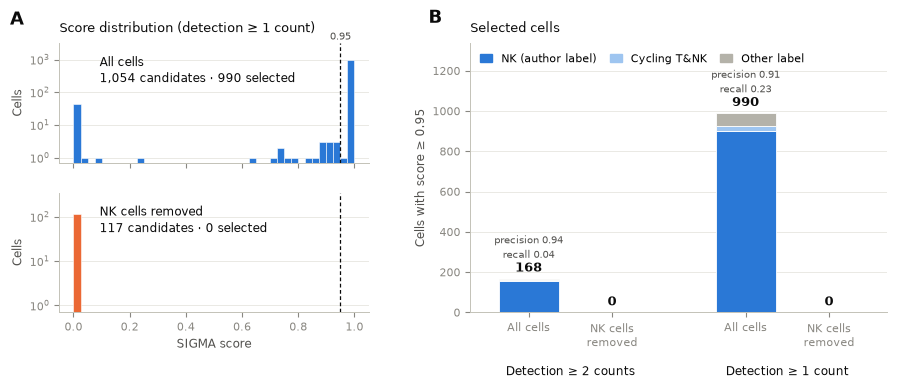

In [8]:
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, LIGHT_BLUE, ORANGE, GREY = "#2a78d6", "#9ec5f0", "#eb6834", "#b4b2a9"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9.5, "axes.labelsize": 8.5, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "legend.fontsize": 8, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.7, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlecolor": INK,
    "axes.titlepad": 8, "pdf.fonttype": 42,
})
SHOWN = 1  # detection threshold shown in panel A


def panel_label(ax, letter, x=-0.16, y=1.06):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=13, fontweight="bold",
            color=INK, va="bottom")


def threshold_label(t):
    return f"≥ {t} count" + ("s" if t > 1 else "")


fig = plt.figure(figsize=(9, 3.9))
gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 1.35], hspace=0.25, wspace=0.28,
              left=0.07, right=0.99, top=0.86, bottom=0.17)

# A: score distribution of the candidates, one row per input
shown = {r["input"]: r for r in runs if r["threshold"] == SHOWN}
bins = np.linspace(0, 1, 41)
ax_top = None
for row, (key, color, title) in enumerate([("all_NK", BLUE, "All cells"),
                                           ("no_NK", ORANGE, "NK cells removed")]):
    ax = fig.add_subplot(gs[row, 0], sharex=ax_top)
    ax_top = ax_top or ax
    s = shown[key]["obs"]["score"] if "score" in shown[key]["obs"] else pd.Series(dtype=float)
    ax.hist(s, bins=bins, color=color, edgecolor="white", linewidth=0.4)
    ax.axvline(SCORE_THRESHOLD, color=INK, lw=0.9, ls=(0, (3, 2)))
    ax.set_yscale("log")
    ax.set_ylim(0.7, max(len(s), 10) * 3)
    ax.grid(axis="y", color=GRID, lw=0.5, which="major")
    ax.set_axisbelow(True)
    n_sel = int((s >= SCORE_THRESHOLD).sum())
    ax.text(0.13, 0.92, f"{title}\n{len(s):,} candidates · {n_sel:,} selected",
            transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color=INK, linespacing=1.4)
    ax.minorticks_off()
    ax.set_ylabel("Cells")
    if row == 0:
        ax.set_title(f"Score distribution (detection {threshold_label(SHOWN)})", loc="left")
        ax.tick_params(labelbottom=False)
        panel_label(ax, "A", y=1.12)
    else:
        ax.set_xlabel("SIGMA score")
ax_top.text(SCORE_THRESHOLD, 1.01, f"{SCORE_THRESHOLD}", transform=ax_top.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=7.5, color=INK2)

# B: selected cells by author label, grouped by detection threshold
ax = fig.add_subplot(gs[:, 1])
order = summary.sort_values(["detection_threshold", "input"], ascending=[False, True]).reset_index(drop=True)
gap = 0.6
xs = np.array([i + gap * (i // 2) for i in range(len(order))], dtype=float)
width = 0.72
parts = [("selected_nk", BLUE, "NK (author label)"),
         ("selected_ambiguous", LIGHT_BLUE, "Cycling T&NK"),
         ("selected_other", GREY, "Other label")]
bottom = np.zeros(len(order))
for col, color, _ in parts:
    ax.bar(xs, order[col], bottom=bottom, color=color, width=width, edgecolor="white", linewidth=0.6)
    bottom += order[col].values
top = max(order["selected"].max(), 1)
for xi, r in zip(xs, order.itertuples()):
    ax.text(xi, r.selected + top * 0.02, f"{r.selected:,}", ha="center", va="bottom",
            fontsize=9, fontweight="bold", color=INK)
    if r.input == "all_NK":
        ax.text(xi, r.selected + top * 0.09,
                f"precision {r.precision_nk:.2f}\nrecall {r.recall_nk:.2f}",
                ha="center", va="bottom", fontsize=7.5, color=INK2, linespacing=1.3)
ax.set_xticks(xs)
ax.set_xticklabels(["All cells" if i == "all_NK" else "NK cells\nremoved" for i in order["input"]])
for k, t in enumerate(order["detection_threshold"].unique()):
    centre = xs[order["detection_threshold"] == t].mean()
    ax.text(centre, -0.2, f"Detection {threshold_label(t)}", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8.5, color=INK)
ax.set_ylim(0, top * 1.35)
ax.set_xlim(xs[0] - 0.7, xs[-1] + 0.7)
ax.set_ylabel(f"Cells with score ≥ {SCORE_THRESHOLD}")
ax.grid(axis="y", color=GRID, lw=0.5)
ax.set_axisbelow(True)
ax.set_title("Selected cells", loc="left")
ax.legend(handles=[Patch(color=c, label=l) for _, c, l in parts], frameon=False,
          loc="upper left", ncol=3, bbox_to_anchor=(0, 1.0), handlelength=1.1, columnspacing=1.2)
panel_label(ax, "B", x=-0.1, y=1.06)

fig.savefig(os.path.join(FIG_DIR, "figure_S4.pdf"), bbox_inches="tight", dpi=500)
fig.savefig(os.path.join(FIG_DIR, "figure_S4.png"), bbox_inches="tight", dpi=250)
plt.show()

## Why are Tem/emra CD8 T cells selected with NK cells present but not after NK removal?
Same 96 Tem/emra cells pass the prefilter in all_NK_t1 and no_NK_t1. Compare their target probability, T-cell exclusion probability and score between runs, and the T-cell exclusion mixture each run fitted.

In [9]:
# Tem/emra CD8 T cells present in the candidates of both runs (detection >= 1 count)
TEM = "Tem/emra_CD8"
T_GENES = EXCLUDE["T_cells"]
obs_by = {r["name"]: r["obs"].copy() for r in runs if r["threshold"] == 1}
for o in obs_by.values():
    o["label"] = labels.reindex(o.index).astype(str)
print("Output columns:", list(next(iter(obs_by.values())).columns))
t_col = next(c for c in next(iter(obs_by.values())).columns if c.startswith("proba_") and "T_cell" in c)

shared = obs_by["all_NK_t1"].index.intersection(obs_by["no_NK_t1"].index)
tem = [i for i in shared if labels[i] == TEM]
print(f"Tem/emra candidates in both runs: {len(tem)}")

# Mean log1p-CPM of the T-cell exclusion genes, computed as SIGMA does, for all candidates of each run
def t_mean(idx):
    sub = adata[idx]
    X = sub.X.toarray() if hasattr(sub.X, "toarray") else np.asarray(sub.X)
    cpm = np.log1p(X / X.sum(1, keepdims=True) * 1e6)
    cols = [sub.var_names.get_loc(g) for g in T_GENES if g in sub.var_names]
    return pd.Series(cpm[:, cols].mean(1), index=idx)

cols = ["target_mean_expr", "proba_target", t_col, "score"]
comp = pd.concat({n: o.loc[tem, [c for c in cols if c in o]] for n, o in obs_by.items()}, axis=1)
comp[("T_mean", "")] = t_mean(pd.Index(tem))
print("\nPer-cell values of the Tem/emra cells, both runs (median and quartiles):")
print(comp.describe().loc[["25%", "50%", "75%"]].round(3).T.to_string())
sel_all = obs_by["all_NK_t1"].loc[tem, "score"] >= SCORE_THRESHOLD
print(f"\nSelected in all_NK_t1: {sel_all.sum()} / {len(tem)}")
print("T_mean of selected vs non-selected Tem/emra (median):",
      comp.loc[sel_all, ("T_mean", "")].median().round(3), "vs",
      comp.loc[~sel_all, ("T_mean", "")].median().round(3))

# T-cell mean expression over all candidates: composition of the data each T exclusion GMM was fitted on
for n, o in obs_by.items():
    tm = t_mean(o.index)
    is_tem = o["label"].eq(TEM)
    print(f"\n{n}: {len(o):,} candidates, T_mean median {tm.median():.2f} "
          f"(NK-labelled: {tm[o['label'].str.contains(NK_PATTERN)].median():.2f}; Tem/emra: {tm[is_tem].median():.2f}); "
          f"zero T_mean: {(tm == 0).mean():.0%}")

# What SIGMA logged about the T-cell exclusion mixture (components, means, target components)
for n in obs_by:
    print(f"\n=== {n}.log, lines about T_cells / components")
    for line in open(os.path.join(WORK_DIR, f"{n}.log")):
        if re.search(r"T_cells|component|Ashman|means?|K =|n_components", line, re.I):
            print(line.rstrip()[:200])
    print("plots:", sorted(os.listdir(os.path.join(WORK_DIR, "plots", n))) if os.path.isdir(os.path.join(WORK_DIR, "plots", n)) else "none")


Output columns: ['Organ', 'Donor', 'Chemistry', 'Cell_category', 'Predicted_labels_CellTypist', 'Majority_voting_CellTypist', 'Majority_voting_CellTypist_high', 'Manually_curated_celltype', 'Sex', 'Age_range', 'target_mean_expr', 'exclude_mean_expr_T_cells', 'exclude_mean_expr_B_cells', 'exclude_mean_expr_Monocytes', 'proba_target', 'proba_T_cells', 'proba_B_cells', 'proba_Monocytes', 'score', 'label']
Tem/emra candidates in both runs: 96

Per-cell values of the Tem/emra cells, both runs (median and quartiles):
                              25%    50%    75%
all_NK_t1 target_mean_expr  3.880  4.629  4.842
          proba_target      1.000  1.000  1.000
          proba_T_cells     0.000  0.011  0.984
          score             0.016  0.989  1.000
no_NK_t1  target_mean_expr  3.880  4.629  4.842
          proba_target      1.000  1.000  1.000
          proba_T_cells     1.000  1.000  1.000
          score             0.000  0.000  0.000
T_mean                      3.382  3.989  4.583

Se